# An asteroid that brightened: finding comet-like activity in the astrometric archive

**The question.** Every astrometric report carries a magnitude. For an inactive asteroid those
magnitudes follow from its orbit and its absolute magnitude H: the distance to the Sun and to the
observer, plus the H,G phase law, predict how bright it should look on any night, to within the
noise and the station-to-station offsets that [notebook 08](08_photometry_h_phase.ipynb) measures.
An *active* asteroid breaks that rule. When it sheds dust, from a rotational breakup, an impact or
sublimating ice, the dust scatters sunlight too, and the object reports **brighter** than its
orbit and H predict. Can we find such episodes by scanning the archive's own magnitudes, and do
their dates and sizes agree with what the discoverers published?

**Test cases.**

* **(6478) Gault**, a few-kilometre inner-main-belt asteroid that grew two long dust tails in late 2018 and
  early 2019. Its tails were reported by ATLAS on 2018 December 8; the ZTF survey's photometry
  then showed the first outburst had begun around **2018 October 18 ± 5 d**, a second around
  **December 24 ± 1 d**, and that Gault was **~2.4 mag** above its baseline at the peak
  (Ye et al. 2019, ApJL 874, L16). Jewitt et al. (2019, ApJL 876, L19) date three ejection
  episodes from the tails: 2018 Oct 28 ± 5, Dec 31 ± 5 and 2019 Feb 10 ± 7. Kleyna et al. (2019,
  ApJL 874, L20) argue the cause is a rotational instability driven by the YORP effect.
* **433P/(248370) 2005 QN173**, a main-belt comet found active by ATLAS on 2021 July 7, with a tail
  already present in ZTF images from June 11 (Hsieh et al. 2021, ApJL 922, L9). Activity was also
  found in a 2016 archival image (Chandler et al. 2021, ApJL 922, L8), and a third active
  apparition has just been reported for 2026 (Hsieh et al. 2026, RNAAS 10,
  doi:10.3847/2515-5172/ae954a). Activity that returns near each perihelion points to sublimating ice.
* **(9186) Fumikotsukimoto**, the control: a quiet asteroid of the same brightness (H ≈ 14.3) on
  almost the *same orbit* as Gault (a, e, i agree to 0.01 au, 0.01 and 0.3°), so the same surveys
  watch it under the same kind of geometry. Nothing should be found here, and planting synthetic
  outbursts in its magnitudes measures how faint an outburst the method can see.

A PyRoOrb fit converts every magnitude to V and predicts the brightness at every observation
(`FittedOrbit.magnitude_residuals`). Everything below is built on those residuals, with pandas.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.time import Time
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.1


## 1. Three orbits, three photometric archives

One fit per object. The photometry rides along: each fit estimates H the find_orb way (a weighted
mean under the H,G law with G fixed at 0.15) and keeps every magnitude's residual
dMag = observed − predicted.

In [2]:
objects = {"6478": "(6478) Gault", "248370": "433P/(248370) 2005 QN173",
           "9186": "(9186) Fumikotsukimoto (control)"}
fits, mags = {}, {}
for desig, name in objects.items():
    obs = pyroorb.fetch_observations(desig)
    fit = pyroorb.fit_orbit(obs, designation=desig)
    m = pd.DataFrame(fit.magnitude_residuals())
    m = m[m.dmag.notna()].reset_index(drop=True)
    m["year"] = Time(m.jd_utc.values, format="jd").decimalyear
    fits[desig], mags[desig] = fit, m
    H, sH = fit.absolute_magnitude()
    a, e, i = (fit.elements()[k] for k in ("a", "e", "i"))
    print(f"{name:34s} a={a:.3f} au e={e:.3f} i={i:5.2f} deg | {len(obs):5d} obs, "
          f"{len(m):5d} with a magnitude | H = {H:.2f} (G = {fit.slope_parameter()})")

(6478) Gault                       a=2.306 au e=0.193 i=22.81 deg |  4348 obs,  4193 with a magnitude | H = 14.48 (G = 0.15)


433P/(248370) 2005 QN173           a=3.067 au e=0.226 i= 0.07 deg |   881 obs,   858 with a magnitude | H = 15.52 (G = 0.15)


(9186) Fumikotsukimoto (control)   a=2.308 au e=0.192 i=23.10 deg |  5351 obs,  5208 with a magnitude | H = 14.33 (G = 0.15)


## 2. A first look

Before any statistics: every magnitude's residual against time. Brighter than predicted is
**up**.

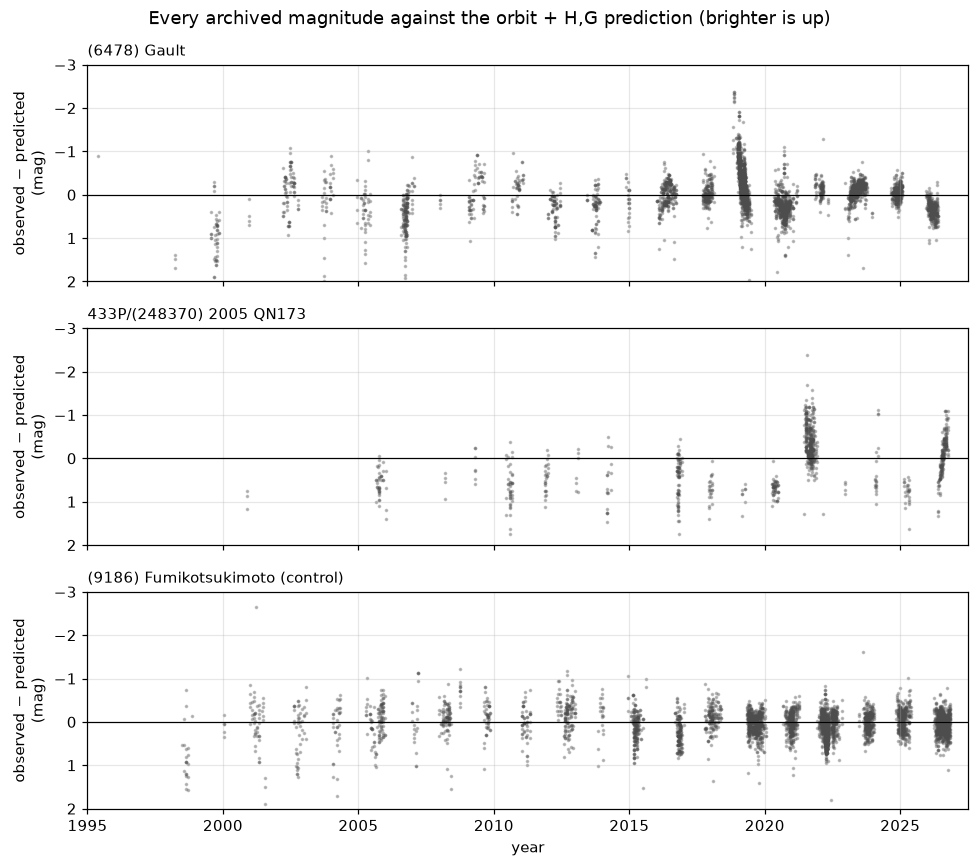

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ax, (desig, name) in zip(axes, objects.items()):
    m = mags[desig]
    ax.scatter(m.year, m.dmag.clip(-3, 3), s=2, alpha=0.3, color="0.3")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylim(2, -3)                                  # brighter is up
    ax.set_ylabel("observed − predicted\n(mag)")
    ax.set_title(name, fontsize=10, loc="left")
axes[-1].set_xlabel("year")
axes[-1].set_xlim(1995, 2027.5)
fig.suptitle("Every archived magnitude against the orbit + H,G prediction (brighter is up)")
fig.tight_layout()
plt.show()

Gault's 2018–19 apparition stands out at once, two magnitudes above everything else, and 433P's
2021 apparition sits a magnitude above its other apparitions, with 2026 rising the same way. The
control has nothing comparable. But the eye also sees the traps. Whole apparitions shift by
±0.3 mag (the changing aspect of an elongated body, the surveys of that year, the phase law), and
the early years, before about 2010, scatter by a magnitude.

## 3. An activity detector in one function

The detector has to separate *the object changed* from *the observers differ*. It works in four
steps.

1. **Station zero points from quiet epochs.** Each station's median residual, measured *only*
   in epochs not (yet) flagged as active, is subtracted from its magnitudes. A station that observed
   only while the object was active has no quiet epoch to calibrate on. Its magnitudes are
   shown but not used. Without that rule, the many observers who joined only *because* Gault was
   active would calibrate the activity away.
2. **One value per night.** Each station's nightly median is combined into a weighted mean, the
   weights coming from that station's own scatter in quiet epochs. A pre-2010 survey with
   0.5 mag scatter per magnitude counts for less than a modern one with 0.15.
3. **A noise model from the data.** A night's uncertainty is its statistical part plus a
   systematic floor, the night-to-night scatter of quiet nights (apparition-to-apparition
   wander included). The first pass knows no quiet epochs yet, so it measures that floor from
   *differences* between nights less than ten days apart, which a month-long brightening hardly
   changes. Its single zero point is the median of the per-year medians, so that a busy active
   year cannot set it.
4. **An episode** is at least three nights more than 3σ **brighter** than the baseline, from at
   least two different stations, with no gap longer than 60 days. Real activity brightens the
   object for every telescope, while a pipeline glitch affects only one. Nights that are *fainter*
   are not tested. The episode is masked as non-quiet, and steps 1–4 repeat until nothing changes.

The same settings (3σ, 3 nights, 2 stations, 60 days) run on all three objects. To be clear about
how they were reached: they were shaped on these same three objects. A first, simpler version
used one noise level for every station and had no two-station rule. It raised false alarms on
the control's 1990s–2000s photometry, and its noise estimate, inflated by 433P's many active
nights, missed 433P altogether. Steps 2–4 fixed that. Nothing was adjusted to match a published
date or amplitude. §6 measures what the final version can and cannot detect; a fair test of its
false-alarm rate would be a fresh set of objects.

In [4]:
def robust_sigma(x):
    """Standard deviation from the median absolute deviation (insensitive to outliers)."""
    x = np.asarray(x, float)
    return 1.4826 * np.median(np.abs(x - np.median(x)))

def activity_scan(m, z_cut=3.0, min_nights=3, min_stations=2, gap_days=60, min_quiet=5,
                  n_iter=6):
    """Find epochs when an object reported brighter than its orbit + H,G predict.

    m: a DataFrame of fit.magnitude_residuals() (rows with a dmag). Returns (m, nights,
    episodes, noise): m with per-observation 'corr' (station-corrected dmag), 'quiet' and
    'calibrated'; one row per night; the episodes as (first night, last night, number of
    flagged nights, stations); and the noise model (per-station sigma, night-level sigma).
    """
    m = m.copy()
    m["night"] = np.floor(m.jd_utc).astype(int)         # UTC noon to noon
    m["quiet"] = True
    first = True
    for _ in range(n_iter):
        q = m[m.quiet]
        if first:
            # Pass 1 knows no quiet epochs yet: one zero point for everybody, the median of
            # the per-year medians, so that one busy active year cannot set it.
            year = np.floor((m.jd_utc - 2451544.5) / 365.25)
            offset = pd.Series(m.dmag.groupby(year).median().median(), index=m.obscode.unique())
        else:
            # Later passes: each station's own zero point, from its quiet epochs only.
            n_quiet = q.groupby("obscode").dmag.size()
            offset = q.groupby("obscode").dmag.median()[n_quiet >= min_quiet]
        m["calibrated"] = m.obscode.isin(offset.index)
        m["corr"] = m.dmag - m.obscode.map(offset)
        c = m[m.calibrated]
        # Noise of ONE magnitude from each station, measured on its quiet residuals.
        sig_st = (c[c.quiet].groupby("obscode")["corr"].agg(robust_sigma).clip(lower=0.1)
                  .reindex(offset.index).fillna(0.5))
        sn = (c.groupby(["night", "obscode"])            # one value per station and night
                .agg(jd=("jd_utc", "median"), dm=("corr", "median"), n=("corr", "size"),
                     quiet=("quiet", "all")).reset_index())
        sn["w"] = sn.n / sn.obscode.map(sig_st) ** 2
        sn["wdm"] = sn.w * sn.dm
        g = sn.groupby("night")
        nights = pd.DataFrame({"jd": g.jd.median(), "dm": g.wdm.sum() / g.w.sum(),
                               "var_stat": 1 / g.w.sum(), "n": g.n.sum(),
                               "stations": g.obscode.agg(lambda s: ",".join(sorted(s))),
                               "quiet": g.quiet.all()})
        qn = nights[nights.quiet]
        if first:   # night-to-night jitter from nights < 10 d apart: blind to month-long trends
            close = np.diff(nights.index.values) < 10
            spread = robust_sigma(np.diff(nights.dm.values)[close]) / np.sqrt(2)
        else:       # scatter of the quiet nights, apparition-to-apparition wander included
            spread = robust_sigma(qn.dm)
        sig_sys = np.sqrt(max(spread**2 - np.median(qn.var_stat), 0.0))
        nights["sigma"] = np.sqrt(sig_sys**2 + nights.var_stat)
        nights["z"] = nights.dm / nights.sigma
        flagged = nights[nights.z < -z_cut]                       # brighter only
        episodes = []
        if len(flagged):
            group = (flagged.index.to_series().diff() > gap_days).cumsum().values
            for _, f in flagged.groupby(group):
                stations = sorted(set(",".join(f.stations).split(",")))
                if len(f) >= min_nights and len(stations) >= min_stations:
                    episodes.append((f.index.min(), f.index.max(), len(f), stations))
        quiet = np.ones(len(m), bool)
        for a, b, *_ in episodes:
            quiet &= ~((m.night >= a) & (m.night <= b))
        if not first and (quiet == m.quiet.values).all():
            break
        m["quiet"] = quiet
        first = False
    return m, nights, episodes, (sig_st, sig_sys)

Run on all three:

In [5]:
def day(night):
    return Time(night + 0.5, format="jd").iso[:10]

scans = {}
for desig, name in objects.items():
    m, nights, episodes, (sig_st, sig_sys) = activity_scan(mags[desig])
    scans[desig] = (m, nights, episodes, sig_sys)
    print(f"{name}: {m.calibrated.mean():.0%} of magnitudes from calibrated stations; "
          f"night-level scatter {sig_sys:.2f} mag; {len(episodes)} episode(s)")
    for a, b, k, st in episodes:
        before = nights[nights.index < a]
        ep = nights.loc[a:b]
        print(f"   {day(a)} .. {day(b)}: {k} of {len(ep)} nights flagged, {len(st)} stations; "
              f"previous night with data {day(before.index.max()) if len(before) else '-'}; "
              f"peak {ep.dm.min():+.2f} mag on {day(ep.dm.idxmin())}")

(6478) Gault: 90% of magnitudes from calibrated stations; night-level scatter 0.17 mag; 2 episode(s)
   2002-06-19 .. 2002-06-30: 3 of 3 nights flagged, 2 stations; previous night with data 2002-06-05; peak -1.11 mag on 2002-06-19
   2018-10-27 .. 2019-03-26: 24 of 66 nights flagged, 16 stations; previous night with data 2018-02-09; peak -2.38 mag on 2018-11-09
433P/(248370) 2005 QN173: 62% of magnitudes from calibrated stations; night-level scatter 0.12 mag; 2 episode(s)
   2021-06-10 .. 2021-11-22: 23 of 28 nights flagged, 6 stations; previous night with data 2021-06-06; peak -2.20 mag on 2021-10-05
   2026-07-09 .. 2026-10-01: 8 of 10 nights flagged, 4 stations; previous night with data 2026-07-07; peak -0.99 mag on 2026-09-13


(9186) Fumikotsukimoto (control): 99% of magnitudes from calibrated stations; night-level scatter 0.13 mag; 0 episode(s)


The control is clean. Gault has its 2018–19 episode, plus a 2002 candidate discussed in §4.
433P has its 2021 and 2026 apparitions.

## 4. Gault: the brightening was in the archive six weeks before it was reported

The 2018–19 light curve, against the published dates:

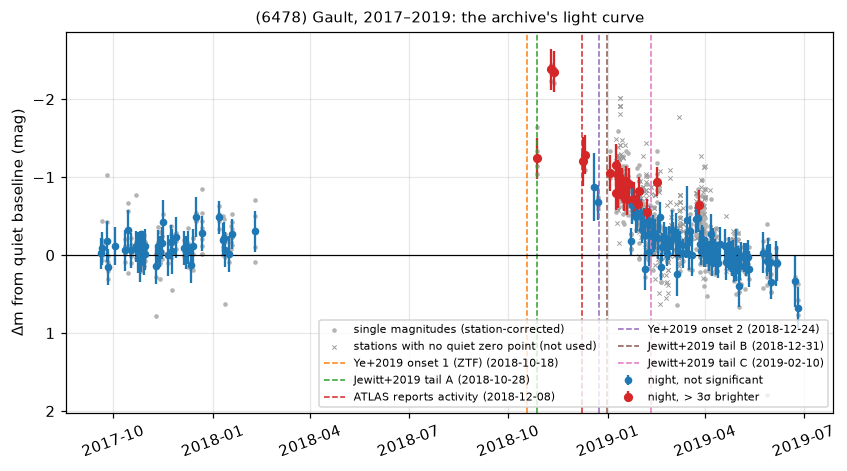

In [6]:
ref_gault = {"Ye+2019 onset 1 (ZTF)": "2018-10-18", "Jewitt+2019 tail A": "2018-10-28",
             "ATLAS reports activity": "2018-12-08",
             "Ye+2019 onset 2": "2018-12-24", "Jewitt+2019 tail B": "2018-12-31",
             "Jewitt+2019 tail C": "2019-02-10"}

def plot_window(desig, start, stop, refs=(), title="", ax=None):
    m, nights, episodes, sig_sys = scans[desig]
    t0, t1 = Time(start).jd, Time(stop).jd
    nn = nights[(nights.jd > t0) & (nights.jd < t1)]
    mm = m[(m.jd_utc > t0) & (m.jd_utc < t1)]
    ax = ax or plt.subplots(figsize=(9, 4.5))[1]
    dt = lambda jd: Time(jd, format="jd").datetime
    cal = mm[mm.calibrated]
    ax.scatter(dt(cal.jd_utc.values), cal["corr"].clip(-4, 2), s=4, color="0.7",
               label="single magnitudes (station-corrected)")
    unc = mm[~mm.calibrated]
    if len(unc):    # no quiet epoch to calibrate on: shown against the median quiet zero point
        zp = m.dmag[m.quiet & m.calibrated].median()
        ax.scatter(dt(unc.jd_utc.values), (unc.dmag - zp).clip(-4, 2), s=8, marker="x", lw=0.6,
                   color="0.6", label="stations with no quiet zero point (not used)")
    flag = nn.z < -3
    ax.errorbar(dt(nn.jd.values[~flag]), nn.dm[~flag], nn.sigma[~flag], fmt="o", ms=4,
                color="C0", label="night, not significant")
    ax.errorbar(dt(nn.jd.values[flag]), nn.dm[flag], nn.sigma[flag], fmt="o", ms=5,
                color="C3", label="night, > 3σ brighter")
    for k, (lab, d) in enumerate(dict(refs).items()):
        ax.axvline(Time(d).datetime, color=f"C{k % 8 + 1}", ls="--", lw=1, label=f"{lab} ({d})")
    ax.axhline(0, color="k", lw=0.8)
    ax.invert_yaxis()
    ax.set_ylabel("Δm from quiet baseline (mag)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, loc="lower right", ncol=2)
    ax.tick_params(axis="x", labelrotation=20)
    return ax

plot_window("6478", "2017-09-01", "2019-07-01", ref_gault,
            "(6478) Gault, 2017–2019: the archive's light curve")
plt.show()

The archive's first flagged night is **2018 October 27**. It comes from the Catalina Sky Survey
(703), routine astrometry for an asteroid nobody yet suspected, with four magnitudes 1.2 mag
brighter than Catalina's own quiet zero point.

The night-by-night values:

In [7]:
m, nights, episodes, _ = scans["6478"]
first_nights = nights.loc[episodes[-1][0]:].head(8)
show = first_nights.assign(date=[day(n) for n in first_nights.index])
print("The first nights of Gault's 2018-19 episode (dm = brightening vs quiet baseline, mag):")
print(show[["date", "stations", "n", "dm", "sigma", "z"]].round(2).to_string(index=False))

The first nights of Gault's 2018-19 episode (dm = brightening vs quiet baseline, mag):
      date stations  n    dm  sigma     z
2018-10-27      703  4 -1.24   0.26 -4.75
2018-11-09      703  4 -2.38   0.26 -9.12
2018-11-12      703  4 -2.35   0.26 -9.01
2018-12-09      T08  1 -1.20   0.31 -3.86
2018-12-11      T05  3 -1.29   0.24 -5.27
2018-12-19      G96  1 -0.87   0.43 -2.00
2018-12-23      T05  4 -0.68   0.23 -2.96
2019-01-03      T05  4 -1.05   0.23 -4.61


How these compare with ZTF's photometry (Ye et al. 2019):

| | the astrometric archive | Ye et al. 2019 (ZTF) |
|---|---|---|
| onset | between 2018 Feb 9 (the last earlier night) and **Oct 27** (first flagged night, already −1.2 mag) | Oct 18 ± 5 d |
| brightness early on | −1.24 mag on Oct 27 | "already ~2 mag above baseline" on Oct 31.5 |
| peak | **−2.38 mag** on Nov 9, −2.35 on Nov 12 | Δmag = **2.4** near Nov 7 |
| second event | the decline turns back: −0.7 on Dec 23, −1.0 to −1.1 from Jan 3 | starts Dec 24–28, +0.6 mag at the Jan 4 peak |

The peak brightening agrees to a few hundredths of a magnitude, even though the two numbers come
from very different photometry: Catalina's routine astrometric magnitudes in one case, ZTF's
calibrated PSF photometry in the other. The Oct 27 night, 1.2 mag up and still rising, fits
the square-law rise from an Oct 18 onset that Ye et al. fit to the ZTF light curve. The
archive cannot pin the onset itself: Gault was not observed between February and late October
2018. The **ATLAS report of 2018 December 8** came six weeks after Catalina's magnitudes already
showed the brightening. Nobody was comparing them with the prediction.

**What the archive does not see.** Chandler et al. (2019, ApJL 877, L12) found faint tails on
Gault in deep DECam images from 2013, 2016 and 2017. The cell below measures the archive in
those windows, together with Gault's 2002 candidate:

In [8]:
def window(desig, start, stop):
    nights = scans[desig][1]
    return nights[(nights.jd >= Time(start).jd) & (nights.jd <= Time(stop).jd)]

print("Gault's earlier, fainter activity seen in deep DECam images (Chandler et al. 2019):")
for a, b in [("2013-09-10", "2013-10-25"), ("2016-05-25", "2016-06-25"),
             ("2017-10-10", "2017-11-25")]:
    w = window("6478", a, b)
    print(f"  {a} .. {b}: {len(w):2d} nights, median dm {w.dm.median():+.2f} mag "
          f"(one night: ±{w.sigma.median():.2f})")

m = scans["6478"][0]
cand = m[(m.jd_utc > Time("2002-05-30").jd) & (m.jd_utc < Time("2002-07-05").jd)]
print("\nThe 2002 candidate, night by night:")
print(cand.assign(date=[day(n) for n in cand.night])
          .groupby(["date", "obscode"]).agg(n=("corr", "size"), band=("band", "first"),
                                            mag=("obs_mag", "median"), dm=("corr", "median"))
          .round(2).to_string())
sig704 = robust_sigma(m["corr"][(m.obscode == "704") & m.quiet])
print(f"LINEAR (704): scatter of one magnitude in quiet epochs {sig704:.2f} mag")

Gault's earlier, fainter activity seen in deep DECam images (Chandler et al. 2019):
  2013-09-10 .. 2013-10-25:  9 nights, median dm +0.11 mag (one night: ±0.21)
  2016-05-25 .. 2016-06-25: 11 nights, median dm -0.18 mag (one night: ±0.23)
  2017-10-10 .. 2017-11-25: 19 nights, median dm -0.06 mag (one night: ±0.23)

The 2002 candidate, night by night:
                    n band   mag    dm
date       obscode                    
2002-06-02 704      3    V  17.6  0.37
2002-06-03 704      5    V  17.5  0.27
2002-06-05 699      1    R  16.2 -0.34
2002-06-19 704      5    V  16.2 -1.11
2002-06-20 704      5    V  16.4 -0.92
2002-06-30 644      3    g  16.6 -0.84
2002-07-02 704      5    V  16.8 -0.65
LINEAR (704): scatter of one magnitude in quiet epochs 0.50 mag


In 2013, 2016 and 2017 the archive shows nothing beyond its ±0.2 mag noise (2016 June is
−0.18 mag, under one night's σ). A thin tail that a 4 m telescope sees at 24th magnitude adds
almost no light inside a survey's photometric aperture. **Activity that changes the total
brightness by less than a few tenths of a magnitude is invisible to this method** (§6
measures the limit).

**The 2002 candidate** rests on LINEAR (704), whose magnitudes scatter by 0.5 mag each in
quiet epochs: its nightly medians jump from +0.3 to −1.1 mag within 16 days at nearly the same
geometry. The one other station involved, NEAT (644), reports −0.84 mag on June 30, so the
episode passes the two-station rule. We know of no published report of activity on Gault in
2002, and three nights of early-survey photometry cannot settle it. It is a candidate that the
archival images (NEAT, LINEAR) could confirm or reject. It is also a reminder that most of the
false alarms come from the pre-2010 surveys.

## 5. 433P: three perihelia, two of them caught

A main-belt comet should be active around perihelion. The fitted orbit gives the perihelion
dates directly: propagate it and find the minima of the heliocentric distance.

In [9]:
fit = fits["248370"]
grid = Time(np.arange(Time("2015-01-01").jd, Time("2027-06-01").jd, 1.0), format="jd")
r = np.linalg.norm(pyroorb.propagate(fit, grid)[:, :3], axis=1)
k = np.where((r[1:-1] < r[:-2]) & (r[1:-1] < r[2:]))[0] + 1
perihelia = [grid[i].iso[:10] for i in k]
print("433P perihelia from the fitted orbit:", ", ".join(f"{p} (q = {r[i]:.3f} au)" for p, i in zip(perihelia, k)))

import json, urllib.request
def sbdb(desig, phys=False):
    url = f"https://ssd-api.jpl.nasa.gov/sbdb.api?sstr={desig}" + ("&phys-par=1" if phys else "")
    return json.load(urllib.request.urlopen(url, timeout=60))
el = {e["name"]: float(e["value"]) for e in sbdb("248370")["orbit"]["elements"]}
print(f"JPL SBDB: next perihelion {Time(el['tp'], format='jd', scale='tdb').iso[:10]}, "
      f"period {el['per']:.0f} d")

433P perihelia from the fitted orbit: 2016-01-03 (q = 2.378 au), 2021-05-14 (q = 2.374 au), 2026-09-23 (q = 2.379 au)


JPL SBDB: next perihelion 2026-09-23, period 1960 d


The fitted orbit's 2026 perihelion falls on the same day as JPL's. The light curves around
the three perihelia, with the published dates marked:

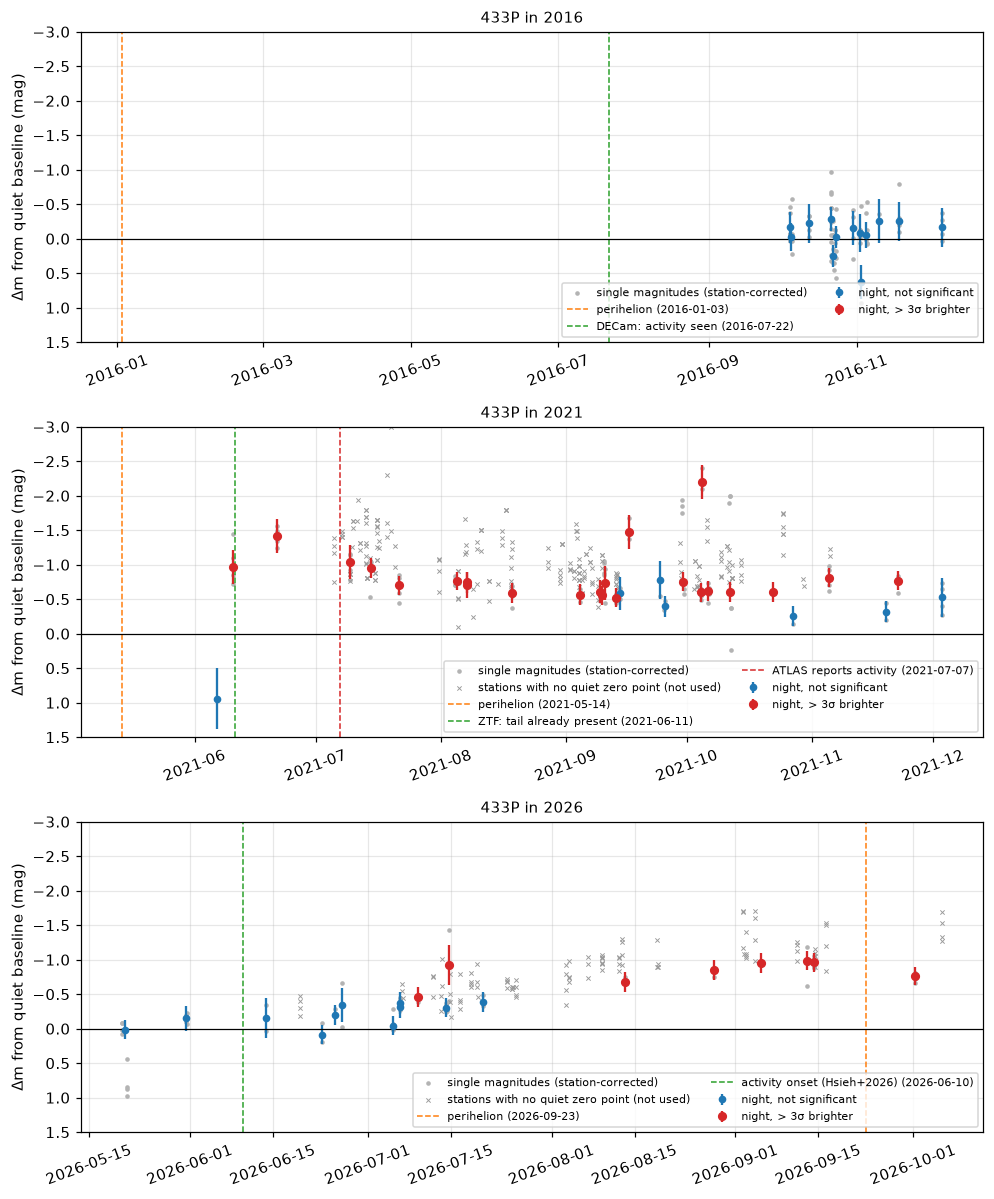

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(9, 11))
plot_window("248370", "2016-04-01", "2017-02-01",
            {"perihelion": perihelia[0], "DECam: activity seen": "2016-07-22"},
            "433P in 2016", ax=axes[0])
plot_window("248370", "2021-03-01", "2022-01-15",
            {"perihelion": perihelia[1], "ZTF: tail already present": "2021-06-11",
             "ATLAS reports activity": "2021-07-07"}, "433P in 2021", ax=axes[1])
plot_window("248370", "2026-03-01", "2026-11-15",
            {"perihelion": perihelia[2], "activity onset (Hsieh+2026)": "2026-06-10"},
            "433P in 2026", ax=axes[2])
for ax in axes:
    ax.set_ylim(1.5, -3)
fig.tight_layout()
plt.show()

**2021.** The first flagged night is **June 10** (Catalina again, −1.0 mag). That is one day
before the earliest ZTF image showing the tail and four weeks before ATLAS's report. The night of
June 6 (one Catalina magnitude, 21.3, *fainter* than predicted, at the survey's faint limit, while
its three companion observations carry no magnitude) cannot show whether the activity had
begun. Numbers to compare with Hsieh et al. 2021:

In [11]:
w = window("248370", "2021-07-08", "2021-08-14")                 # Hsieh et al.'s observing window
coef, cov = np.polyfit(w.jd - w.jd.mean(), w.dm, 1, w=1 / w.sigma, cov="unscaled")
print(f"2021 Jul 8 - Aug 14: {len(w)} nights, median brightening {w.dm.median():+.2f} mag; "
      f"change over 37 d {coef[0] * 37:+.2f} ± {np.sqrt(cov[0, 0]) * 37:.2f} mag (+ = fading)")
ad_an = np.array([1.8, 2.9])                            # Hsieh et al. 2021, Table 1 range
print("Hsieh et al. 2021 dust/nucleus cross-section 1.8-2.9  ->  brightening "
      + " to ".join(f"{-2.5 * np.log10(1 + x):+.2f}" for x in ad_an) + " mag")
for lab, (a, b) in {"2016 Oct-Nov": ("2016-10-01", "2016-11-30"),
                    "2026 Jun": ("2026-06-01", "2026-06-30"),
                    "2026 Aug-Sep": ("2026-08-01", "2026-09-30")}.items():
    w = window("248370", a, b)
    print(f"{lab}: {len(w)} nights, median {w.dm.median():+.2f} mag, "
          f"error of that median ~{1.25 * w.sigma.median() / np.sqrt(len(w)):.2f} mag")
print(f"2016 July 22 DECam: dust/nucleus 0.7 ± 0.3  ->  {-2.5 * np.log10(1.7):+.2f} mag")
m = scans["248370"][0]
june = m[(m.jd_utc > Time("2021-06-01").jd) & (m.jd_utc < Time("2021-06-30").jd)]
print("\n433P, June 2021 (all magnitudes):")
print(june.assign(date=Time(june.jd_utc.values, format="jd").iso)[
    ["date", "obscode", "obs_mag", "band", "corr"]].round(2).to_string(index=False))

2021 Jul 8 - Aug 14: 6 nights, median brightening -0.75 mag; change over 37 d +0.27 ± 0.22 mag (+ = fading)
Hsieh et al. 2021 dust/nucleus cross-section 1.8-2.9  ->  brightening -1.12 to -1.48 mag
2016 Oct-Nov: 12 nights, median -0.12 mag, error of that median ~0.09 mag
2026 Jun: 4 nights, median -0.18 mag, error of that median ~0.12 mag
2026 Aug-Sep: 5 nights, median -0.95 mag, error of that median ~0.08 mag
2016 July 22 DECam: dust/nucleus 0.7 ± 0.3  ->  -0.58 mag

433P, June 2021 (all magnitudes):
                   date obscode  obs_mag band  corr
2021-06-06 11:00:48.746     703    21.34    G  0.94
2021-06-10 10:43:01.192     703    19.51    G -0.85
2021-06-10 10:48:49.872     703    19.64    G -0.72
2021-06-10 10:54:38.635     703    18.91    G -1.45
2021-06-10 11:00:27.587     703    19.26    G -1.10
2021-06-21 10:33:05.805     703    18.75    G -1.49
2021-06-21 10:41:31.073     703    18.89    G -1.35
2021-06-21 10:49:55.807     703    19.00    G -1.24
2021-06-21 10:58:20.937   

* **Amplitude.** Over Hsieh et al.'s observing window (2021 Jul 8 – Aug 14) the archive sees the
  object **~0.75 mag** brighter than its quiet baseline. Their dust-to-nucleus cross-section ratio of
  1.8–2.9 corresponds to **1.1–1.5 mag**. The archive's amplitude is smaller for two identified
  reasons. First, its baseline is the archive's quiet median, which sits 0.2 mag brighter than their
  nucleus (§7), so the same coma looks 0.2 mag weaker against it. Second, they measured in a fixed
  5,000 km aperture, while survey pipelines measure a point source and miss part of the coma.
* **Fading.** Hsieh et al. saw the coma fade by ~0.35 mag in 37 days. The archive's slope over the
  same window is **+0.27 ± 0.22 mag** per 37 days, consistent but on only six calibrated nights
  (most of that summer's observers had no quiet epoch to calibrate on).
* **2016.** The single DECam image of 2016 July 22 shows a dust/nucleus ratio of 0.7 ± 0.3, i.e.
  ~0.6 mag. The archive has no data until October, by which time it shows −0.12 ± 0.09 mag:
  nothing significant. The activity had faded, or was never bright enough for this test.
* **2026.** Hsieh et al. (2026) report activity from **June 10** in deep imaging. In June the
  archive shows −0.18 ± 0.12 mag, not significant, and it flags the episode from **July 9**, by
  which time the object is ~0.5 mag up and still brightening, about −1 mag in August–September
  around perihelion. The method is a month later than the imaging. The tail is visible to
  a large telescope before the object's total brightness changes by the few tenths of a
  magnitude the archive can see. The 2026 apparition is still under way, so these numbers will
  change on a re-run.

## 6. The control: false alarms and the detection limit

On the control the scan found nothing in 5,000 magnitudes over 35 years. To measure what it
*would* have found, we plant synthetic outbursts in its residuals: the object made A mag brighter
for 45 days (about the length of Gault's episodes), starting on 20 random observed nights since
2010, and rerun the scan each time. This is the honest version of a detection limit: the same
code, the same station mix, the same gaps.

In [12]:
m0 = mags["9186"]
rng = np.random.default_rng(2026)
data_nights = np.unique(np.floor(m0.jd_utc[m0.jd_utc > Time("2010-01-01").jd]).astype(int))
starts = rng.choice(data_nights, 20, replace=False)
amplitudes = [0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]
base_nights = scans["9186"][1]
def coverage(s):
    w = base_nights[(base_nights.index >= s) & (base_nights.index < s + 45)]
    return len(w), len(set(",".join(w.stations).split(",")))
eligible = np.array([n >= 3 and k >= 2 for n, k in map(coverage, starts)])
print(f"{eligible.sum()} of {len(starts)} windows hold >= 3 nights from >= 2 calibrated stations")
recovered, recovered_eligible, false_alarms = [], [], 0
for A in amplitudes:
    hits = np.zeros(len(starts), bool)
    for j, s in enumerate(starts):
        m = m0.copy()
        m.loc[(m.jd_utc >= s) & (m.jd_utc < s + 45), "dmag"] -= A    # 45 days, A mag brighter
        episodes = activity_scan(m)[2]
        hits[j] = any(a < s + 45 and b >= s for a, b, *_ in episodes)
        false_alarms += sum(not (a < s + 45 and b >= s) for a, b, *_ in episodes)
    recovered.append(hits.mean())
    recovered_eligible.append(hits[eligible].mean())
    print(f"injected {A:.1f} mag: recovered {hits.sum():2d} of {len(starts)}, "
          f"{hits[eligible].sum():2d} of the {eligible.sum()} well-covered windows")
print(f"episodes found outside the injected windows: {false_alarms} in "
      f"{len(starts) * len(amplitudes)} scans")

16 of 20 windows hold >= 3 nights from >= 2 calibrated stations


injected 0.2 mag: recovered  0 of 20,  0 of the 16 well-covered windows


injected 0.3 mag: recovered  2 of 20,  2 of the 16 well-covered windows


injected 0.4 mag: recovered  6 of 20,  6 of the 16 well-covered windows


injected 0.5 mag: recovered 15 of 20, 15 of the 16 well-covered windows


injected 0.6 mag: recovered 15 of 20, 15 of the 16 well-covered windows


injected 0.8 mag: recovered 16 of 20, 16 of the 16 well-covered windows


injected 1.0 mag: recovered 16 of 20, 16 of the 16 well-covered windows
episodes found outside the injected windows: 0 in 140 scans


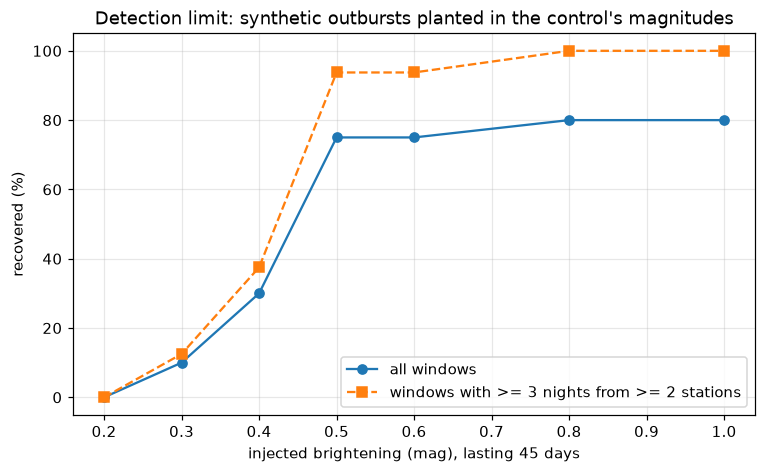

In [13]:
plt.plot(amplitudes, np.array(recovered) * 100, "o-", label="all windows")
plt.plot(amplitudes, np.array(recovered_eligible) * 100, "s--",
         label="windows with >= 3 nights from >= 2 stations")
plt.legend()
plt.xlabel("injected brightening (mag), lasting 45 days")
plt.ylabel("recovered (%)")
plt.title("Detection limit: synthetic outbursts planted in the control's magnitudes")
plt.ylim(-5, 105)
plt.show()

For an object like the control, with Gault's orbit, its brightness and its survey coverage, an
outburst of **≥ 0.5 mag** lasting six weeks is found almost every time the object is being
observed by at least two calibrated stations on three nights. **0.3–0.4 mag** is found
sometimes, and **0.2 mag** never. No planted outburst produced a detection anywhere else:
140 scans without a false alarm on the control's own record. The windows that are never found
at any amplitude are the ones with fewer than three nights or only one station. *Coverage*,
not depth, is then the limit.

This is consistent with §4 and §5. Gault's 2.4 mag outburst and 433P's ~1 mag comae are easy;
Gault's faint 2013–2017 tails and 433P's 2016 activity, if they changed the total brightness at
all, did so by less than this limit.

## 7. What activity does to the catalogue H

The catalogues fit H to *all* the magnitudes, active epochs included. The table compares the H of
the fit (the find_orb-style weighted mean), the median over all magnitudes, and the median over
the quiet epochs only, with the MPC's and JPL's H and, where published, the nucleus H measured by
the discoverers (all with G = 0.15).

In [14]:
def mpc_h(desig):
    req = urllib.request.Request("https://data.minorplanetcenter.net/api/get-orb", method="GET",
                                 data=json.dumps({"desig": desig}).encode(),
                                 headers={"Content-Type": "application/json"})
    md = json.load(urllib.request.urlopen(req, timeout=60))[0]["mpc_orb"][0]["magnitude_data"]
    return md["H"], md["G"]

# Nucleus H in V from the literature, both on the H,G system with G = 0.15:
# Gault, Ye et al. 2019 (pre-outburst ZTF): Hg = 14.81, Hr = 14.31, into V with the transformation
# V = g - 0.565 (g - r) - 0.016 that Hsieh et al. 2021 use; 433P, Hsieh et al. 2021: HV = 16.32.
nucleus = {"6478": 14.81 - 0.565 * (14.81 - 14.31) - 0.016, "248370": 16.32, "9186": np.nan}
rows = []
for desig, name in objects.items():
    m = scans[desig][0]
    H, _ = fits[desig].absolute_magnitude()
    h_mpc, g_mpc = mpc_h(desig)
    h_jpl = next(float(p["value"]) for p in sbdb(desig, phys=True)["phys_par"] if p["name"] == "H")
    print(f"{name}: {(~m.quiet).mean():.0%} of the magnitudes fall in active epochs")
    rows.append({"object": name, "fit H (mean, all)": H,
                 "median, all": H + m.dmag.median(), "median, quiet only": H + m.dmag[m.quiet].median(),
                 "MPC H (G=%.2f)" % g_mpc: h_mpc, "JPL SBDB H": h_jpl,
                 "nucleus, literature": nucleus[desig]})
pd.DataFrame(rows).set_index("object").round(2)

(6478) Gault: 18% of the magnitudes fall in active epochs


433P/(248370) 2005 QN173: 53% of the magnitudes fall in active epochs


(9186) Fumikotsukimoto (control): 0% of the magnitudes fall in active epochs


,"fit H (mean, all)","median, all","median, quiet only",MPC H (G=0.15),JPL SBDB H,"nucleus, literature"
object,,,,,,
(6478) Gault,14.48,14.48,14.57,14.41,14.40,14.51
433P/(248370) 2005 QN173,15.52,15.55,16.12,15.50,15.57,16.32
(9186) Fumikotsukimoto (control),14.33,14.43,14.43,14.32,14.34,NaN


* **433P:** the catalogue H values (MPC 15.50, JPL 15.57) match PyRoOrb's all-data H (15.5), and
  all are **~0.6 mag brighter than the quiet-epoch value (16.1)**, which is in turn within
  0.2 mag of Hsieh et al.'s nucleus, H<sub>V</sub> = 16.32 ± 0.10. Half of 433P's archived
  magnitudes were taken while it was active, so its catalogue H describes the nucleus *plus
  dust*. That makes the reflecting cross-section ~1.7 times too large, and a diameter computed
  from this H with an assumed albedo ~30% too large.
* **Gault:** the active epochs are about a fifth of its record. The quiet-epoch H (14.57) is
  0.09 mag fainter than the all-data value and lands within 0.06 mag of the nucleus value derived
  from ZTF's pre-outburst photometry (14.51). The MPC and JPL values (14.40–14.41) sit in between.
* **The control:** quiet-only and all-data medians agree, as they should. Its fit H and median H
  differ by 0.1 mag, the size of the method dependence (a weighted mean against a median of a
  skewed distribution) in any archival H.

## 8. Traps in the archive

Some of the ways the archive's magnitudes can mislead an activity search, counted:

In [15]:
obs = pyroorb.fetch_observations("248370")
total = [o for o in obs if o.get("nucmag") is not None]
print(f"433P: {len(total)} magnitudes flagged as comet total/nuclear magnitudes "
      f"({sum(1 for o in total if not o['nucmag'])} total, {sum(1 for o in total if o['nucmag'])} nuclear)")
for desig, name in objects.items():
    m, nights, episodes, _ = scans[desig]
    tenth = np.mean(np.isclose(m.obs_mag * 10, np.round(m.obs_mag * 10)))
    active = ~m.quiet
    rej = f"{1 - m.used[active].mean():.0%}" if active.any() else "-"
    print(f"{name:34s} to 0.1 mag: {tenth:4.0%} | no quiet zero point: "
          f"{1 - m.calibrated.mean():4.0%} | set aside by the orbit fit: active epochs {rej}, "
          f"quiet {1 - m.used[~active].mean():.0%}")

433P: 5 magnitudes flagged as comet total/nuclear magnitudes (5 total, 0 nuclear)
(6478) Gault                       to 0.1 mag:  65% | no quiet zero point:  10% | set aside by the orbit fit: active epochs 6%, quiet 1%
433P/(248370) 2005 QN173           to 0.1 mag:  62% | no quiet zero point:  38% | set aside by the orbit fit: active epochs 5%, quiet 1%
(9186) Fumikotsukimoto (control)   to 0.1 mag:  58% | no quiet zero point:   1% | set aside by the orbit fit: active epochs -, quiet 3%


* **Comet magnitude conventions.** Once an object is called a comet, observers may report a
  *total* (coma included) or *nuclear* magnitude, flagged in ADES (`nucMag`) and in column 71 of
  the 80-column format. For 433P only 5 magnitudes carry the flag (all "total"), so the switch
  barely matters here. For a long-known comet it would, and a total magnitude should never be
  compared with an asteroid's H,G prediction as if it were a nucleus.
* **Coarse magnitudes.** About 60% of the magnitudes are reported to 0.1 mag only; nightly
  medians and per-station zero points beat that rounding down, but single magnitudes cannot show a
  0.1 mag event.
* **Who observes depends on the activity.** 10% of Gault's and 38% of 433P's magnitudes come from
  stations with fewer than five quiet-epoch magnitudes, mostly observers who followed the object
  only once it was known to be active. They cannot be calibrated and are left out. Had they been calibrated on their own
  data, the activity would have vanished into their zero points.
* **Active-epoch astrometry is worse.** The orbit fit set aside 5–6% of the active-epoch
  observations but only 1% of the quiet ones: a coma moves the photocentre. The magnitudes are
  kept here regardless (each one has a residual whether or not its position was used).
* **The phase law.** G = 0.15 is assumed for all three objects; a wrong G tilts each apparition
  by up to ~0.2 mag between low and high phase angles. That is part of the ±0.2 mag
  apparition-to-apparition wander the noise model absorbs, and one reason the limit is a few tenths
  of a magnitude rather than a few hundredths.

## Takeaways

* The archive's routine magnitudes, compared with the orbit + H prediction that a PyRoOrb fit
  supplies, **recover both active asteroids' outbursts with no special data**: Gault's
  2018 outburst at **−2.4 mag**, the same peak amplitude ZTF measured, and 433P's 2021 and 2026
  perihelion activity at about −0.7 to −1 mag.
* **The signal was in the archive before the discoveries.** Catalina's magnitudes showed Gault
  1.2 mag too bright on 2018 October 27, six weeks before ATLAS reported tails, and 433P 1 mag too
  bright on 2021 June 10, four weeks before ATLAS's report. A survey comparing every reported
  magnitude with its prediction would have flagged both.
* **The method sees total brightness, not tails.** For a Gault-like object it detects a six-week
  brightening of ≥ 0.5 mag almost whenever two stations observe on three nights, and nothing
  below ~0.3 mag. Gault's faint 2013–2017 tails, 433P's 2016 activity and the first month of its
  2026 activity, all seen in deep images, stay below that.
* **Activity contaminates the catalogue H.** 433P's MPC/JPL H is ~0.6 mag brighter than its quiet
  epochs, while the quiet-epoch value lands within 0.2 mag of the published nucleus magnitude.
  For any active object, compute H from the quiet epochs.

**Caveats.** Astrometric magnitudes are not calibrated photometry: band conversions, catalogue
zero points and pipelines differ by tenths of a magnitude, each magnitude samples a random phase
of the lightcurve, and none carries an uncertainty, so the noise model here is estimated from the
data themselves. The detector's settings were chosen once and not tuned, and they produce one
unconfirmed candidate (Gault, 2002) from early survey photometry. Survey magnitudes measure a
point source in a small aperture, so the amplitude of an extended coma is underestimated against
fixed-aperture photometry (433P: ~0.75 against 1.1–1.5 mag). The 2026 apparition of 433P is still
being observed, and a re-run will give somewhat different 2026 numbers.